In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import fashion_mnist

In [4]:
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [5]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (60000, 28, 28)
y_train: (60000,)
X_test: (10000, 28, 28)
y_test: (10000,)


In [6]:


class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

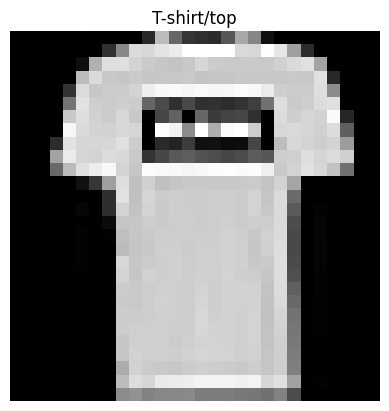

In [8]:
plt.imshow(X_train[1], cmap="gray")
plt.title(class_names[y_train[1]])
plt.axis("off")
plt.show()

In [9]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [ ]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1) #-1 checks dimensions automatically

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

In [12]:
model = Sequential([
    Conv2D(
        32,
        (3, 3),
        activation='relu',
        input_shape=(28, 28, 1)
    ),

    MaxPooling2D((2, 2)),

    Conv2D(
        64,
        (3, 3),
        activation='relu'
    ),

    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dense(10, activation='softmax')
])

/home/kniti/Downloads/ADS/myenv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1789321185.570050    7091 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


In [13]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [14]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8295 - loss: 0.4740 - val_accuracy: 0.8719 - val_loss: 0.3561
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8851 - loss: 0.3182 - val_accuracy: 0.8904 - val_loss: 0.3029
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8998 - loss: 0.2713 - val_accuracy: 0.9016 - val_loss: 0.2762
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9120 - loss: 0.2369 - val_accuracy: 0.8987 - val_loss: 0.2765
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9207 - loss: 0.2108 - val_accuracy: 0.9035 - val_loss: 0.2611
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9293 - loss: 0.1864 - val_accuracy: 0.9071 - val_loss: 0.2490
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9382 - loss: 0.1659 - val_accuracy: 0.9103 - val_loss: 0.2511
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9447 - loss: 0.1476 - 

In [15]:
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9060 - loss: 0.3043


[0.30433669686317444, 0.906000018119812]

In [16]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9060 - loss: 0.3043
Test Loss: 0.30433669686317444
Test Accuracy: 0.906000018119812


In [17]:
predictions = model.predict(X_test)
print(predictions.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
(10000, 10)


In [27]:
print(predictions[0])

np.set_printoptions(suppress=True, precision=4)

print(predictions)

[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
[[0.     0.     0.     ... 0.     0.     1.    ]
 [0.     0.     1.     ... 0.     0.     0.    ]
 [0.     1.     0.     ... 0.     0.     0.    ]
 ...
 [0.     0.     0.     ... 0.     1.     0.    ]
 [0.     1.     0.     ... 0.     0.     0.    ]
 [0.     0.     0.     ... 0.0047 0.0001 0.    ]]


In [21]:
predicted_class = np.argmax(predictions[4])

print("Predicted:", class_names[predicted_class])
print("Actual:", class_names[y_test[4]])

Predicted: Shirt
Actual: Shirt


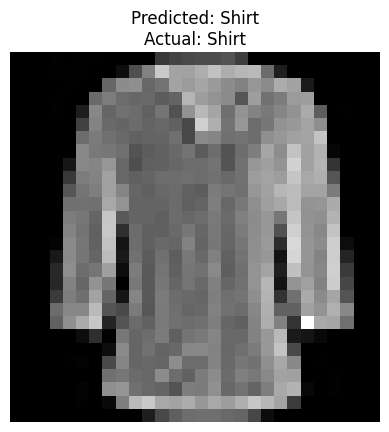

In [24]:
plt.imshow(X_test[4].squeeze(), cmap="gray")

plt.title(
    f"Predicted: {class_names[predicted_class]}\n"
    f"Actual: {class_names[y_test[4]]}"
)

plt.axis("off")
plt.show()

In [28]:
predictions = model.predict(X_test)
y_pred = np.argmax(predictions, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

In [30]:
print(cm.shape)

(10, 10)


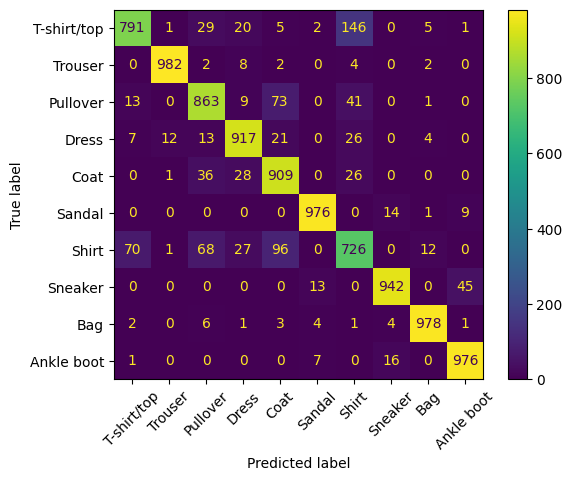

In [31]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(xticks_rotation=45)
plt.show()

In [32]:
cm_no_diag = cm.copy()

np.fill_diagonal(cm_no_diag, 0)

In [33]:
i, j = np.unravel_index(
    np.argmax(cm_no_diag),
    cm_no_diag.shape
)

print("Actual:", class_names[i])
print("Predicted:", class_names[j])
print("Number:", cm[i, j])

Actual: T-shirt/top
Predicted: Shirt
Number: 146


In [34]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9610 - loss: 0.1006 - val_accuracy: 0.9094 - val_loss: 0.3040
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9677 - loss: 0.0866 - val_accuracy: 0.9092 - val_loss: 0.3130
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9709 - loss: 0.0769 - val_accuracy: 0.9143 - val_loss: 0.3416
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9747 - loss: 0.0684 - val_accuracy: 0.9109 - val_loss: 0.3531
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9777 - loss: 0.0604 - val_accuracy: 0.9123 - val_loss: 0.3639
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9787 - loss: 0.0557 - val_accuracy: 0.9121 - val_loss: 0.3686
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9821 - loss: 0.0479 - val_accuracy: 0.9064 - val_loss: 0.4296
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9834 - loss: 0.0440 - 

In [35]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


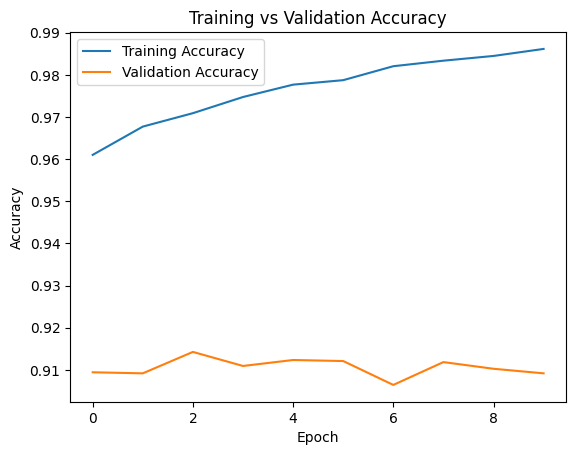

In [36]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.show()

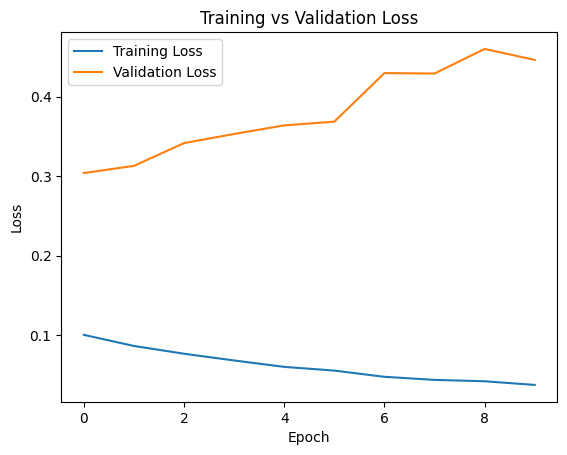

In [37]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.show()

In [38]:
history.history['val_loss']

[0.30401262640953064,
 0.3129986524581909,
 0.3416297733783722,
 0.3530968725681305,
 0.36392858624458313,
 0.36859220266342163,
 0.42960840463638306,
 0.429093599319458,
 0.46001705527305603,
 0.44621244072914124]

In [ ]:
#EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [39]:
y_pred = np.argmax(predictions, axis=1)

In [40]:
incorrect = np.where(y_pred != y_test)[0]

print("Number of incorrect predictions:", len(incorrect))

Number of incorrect predictions: 940


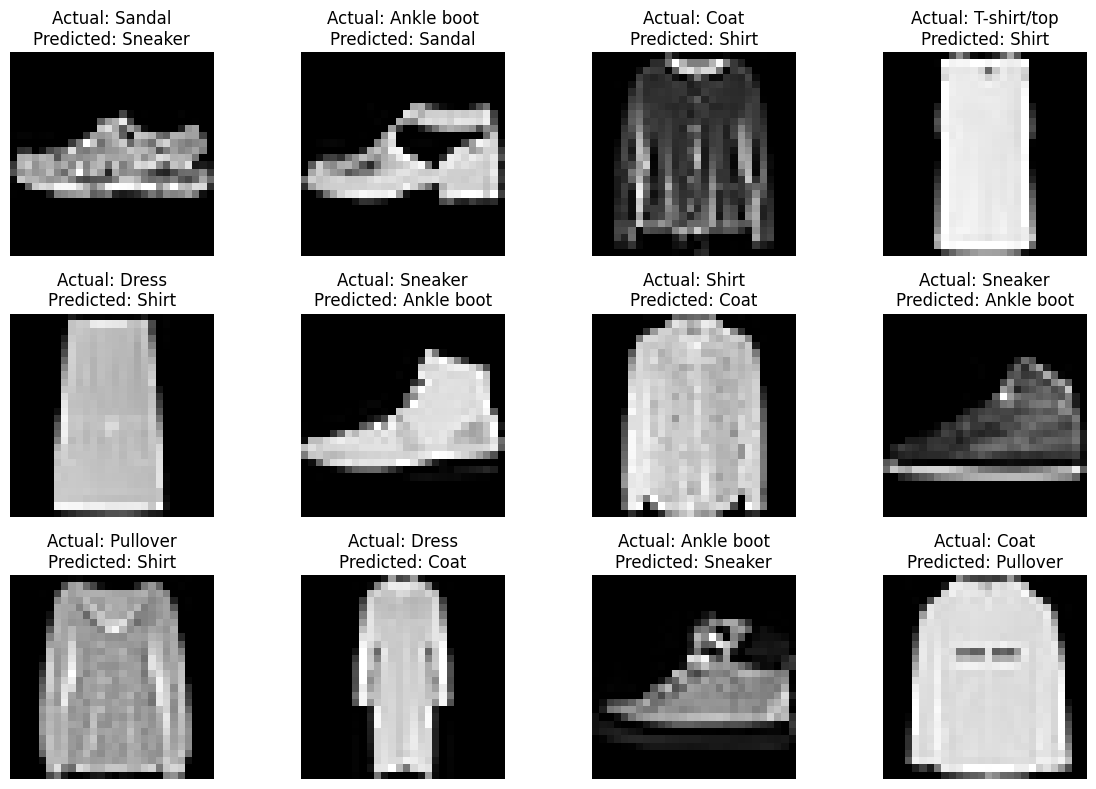

In [41]:
plt.figure(figsize=(12, 8))

for i, idx in enumerate(incorrect[:12]):
    
    plt.subplot(3, 4, i + 1)

    plt.imshow(X_test[idx].squeeze(), cmap="gray")

    plt.title(
        f"Actual: {class_names[y_test[idx]]}\n"
        f"Predicted: {class_names[y_pred[idx]]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

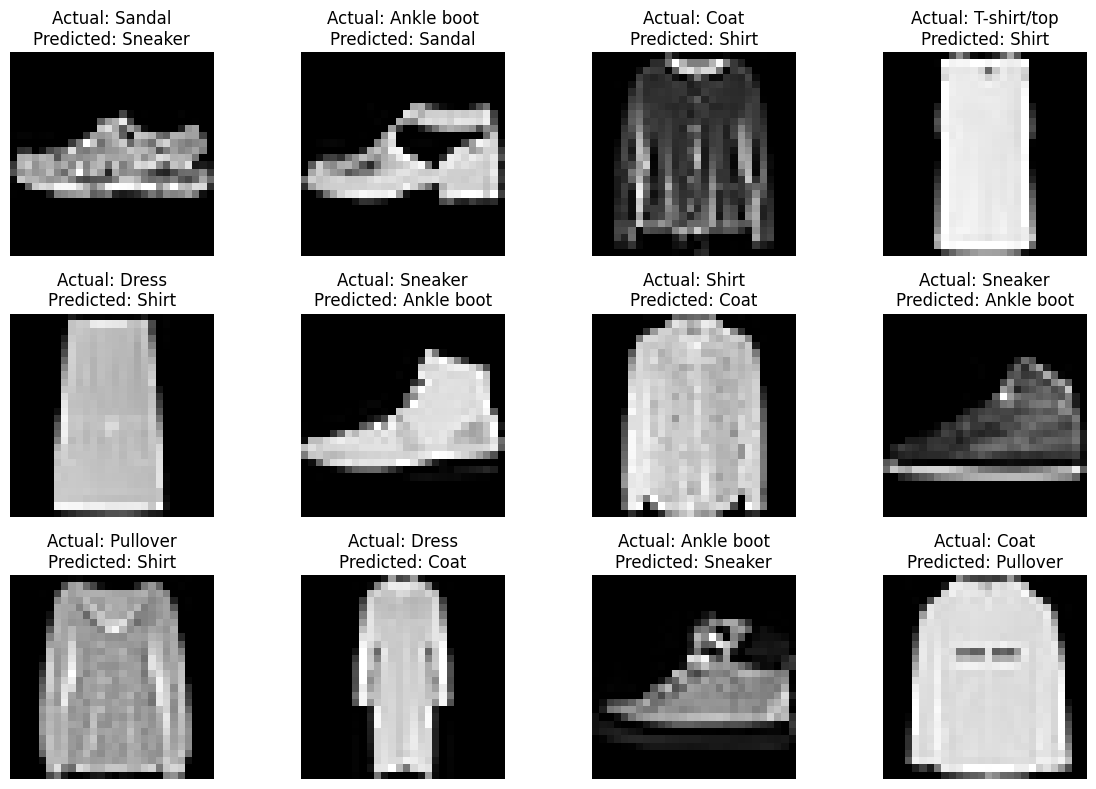

In [42]:
plt.figure(figsize=(12, 8))

for i, idx in enumerate(incorrect[:12]):
    
    plt.subplot(3, 4, i + 1)

    plt.imshow(X_test[idx].squeeze(), cmap="gray")

    plt.title(
        f"Actual: {class_names[y_test[idx]]}\n"
        f"Predicted: {class_names[y_pred[idx]]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()